# Detecção de Crises Epilépticas em Sinais de EEG (CHB-MIT)

Este notebook apresenta um pipeline completo para processamento, análise e classificação de sinais de Eletroencefalograma (EEG) provenientes da base de dados **CHB-MIT** (especificamente o canal e arquivos do paciente `chb24`).

O objetivo principal é identificar automaticamente intervalos de crises epilépticas (anomalias) utilizando técnicas clássicas de Aprendizado de Máquina (Machine Learning) e redes neurais artificiais.

---

## 📋 Estrutura do Projeto

1. **Instalação e Importação de Dependências**: Utilização da biblioteca especializada `MNE` para manipulação de dados neurofisiológicos, além de `scikit-learn`, `numpy` e `matplotlib`.
2. **Carregamento e Exploração de Dados**: Leitura de arquivos `.edf` contendo múltiplos canais de EEG e mapeamento de metadados.
3. **Filtragem de Sinais**: Aplicação de filtros passa-banda (0.5 - 40 Hz) para remoção de ruídos de alta frequência e desvios de linha de base.
4. **Janelamento (Sliding Window)**: Divisão do sinal contínuo em janelas temporais de 1 segundo (256 amostras) com sobreposição de 50% (passo de 128 amostras).
5. **Extração de Características**: Geração de estatísticas básicas por canal (Média, Desvio Padrão, Mínimo e Máximo) servindo como entrada para os classificadores.
6. **Rotulamento Automatizado**: Cruzamento dos tempos de amostragem de cada janela com as anotações médicas fornecidas pelo sumário oficial do dataset.
7. **Modelagem de Machine Learning**:
   * **Árvore de Decisão (`DecisionTreeClassifier`)** como baseline.
   * **Rede Neural Multi-Layer Perceptron (`MLPClassifier`)** para classificação robusta.
8. **Explicação de Resultados com GenAI**: Integração com API de LLM para gerar relatórios e interpretações automatizadas a partir das predições do modelo.

---

## 📊 Resultados e Desempenho

* **Acurácia obtida**: Superior a **98%** em ambos os modelos treinados.
* **Desbalanceamento tratado**: O pipeline lida com um número significativamente maior de janelas normais (~7000) em relação a janelas contendo atividade epiléptica (~100).

---

## 🛠️ Tecnologias Utilizadas
* **Python 3**
* **MNE-Python** (Análise de dados de EEG)
* **Scikit-Learn** (Árvores de Decisão e MLPs)
* **Matplotlib & Seaborn** (Visualizações temporais e marcações de crises)

In [1]:
!pip install mne -q

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ipython 7.34.0 requires jedi>=0.16, which is not installed.
moviepy 1.0.3 requires decorator<5.0,>=4.0.2, but you have decorator 5.3.1 which is incompatible.


In [2]:
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
arquivo_edf = "chb24_01.edf"
raw = mne.io.read_raw_edf(arquivo_edf, preload=True)
raw

Extracting EDF parameters from chb24_01.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 921599  =      0.000 ...  3599.996 secs...


/tmp/ipykernel_2749/2877399466.py:2: RuntimeWarning: Channel names are not unique, found duplicates for: {'T8-P8'}. Applying running numbers for duplicates.
  raw = mne.io.read_raw_edf(arquivo_edf, preload=True)


<RawEDF | chb24_01.edf, 23 x 921600 (3600.0 s), ~161.7 MiB, data loaded>

In [4]:
print(raw.info)
print(raw.ch_names)
print(f"Taxa de amostragem: {raw.info['sfreq']} HZ")

<Info | 8 non-empty values
 bads: []
 ch_names: FP1-F7, F7-T7, T7-P7, P7-O1, FP1-F3, F3-C3, C3-P3, P3-O1, ...
 chs: 23 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 128.0 Hz
 meas_date: 2074-01-25 16:26:28 UTC
 nchan: 23
 projs: []
 sfreq: 256.0 Hz
 subject_info: <subject_info | his_id: Surrogate>
>
['FP1-F7', 'F7-T7', 'T7-P7', 'P7-O1', 'FP1-F3', 'F3-C3', 'C3-P3', 'P3-O1', 'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2', 'FP2-F8', 'F8-T8', 'T8-P8-0', 'P8-O2', 'FZ-CZ', 'CZ-PZ', 'P7-T7', 'T7-FT9', 'FT9-FT10', 'FT10-T8', 'T8-P8-1']
Taxa de amostragem: 256.0 HZ


Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


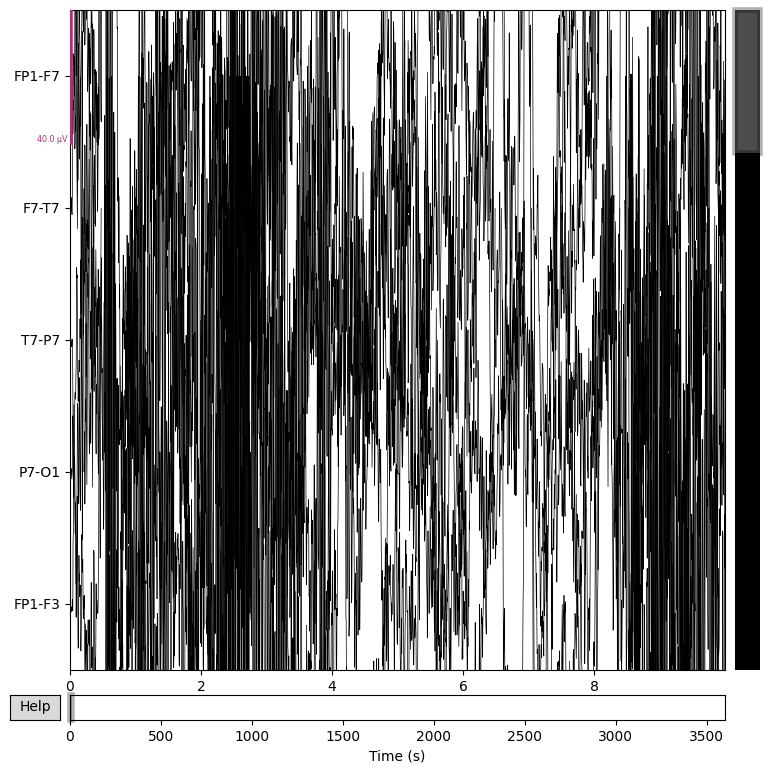

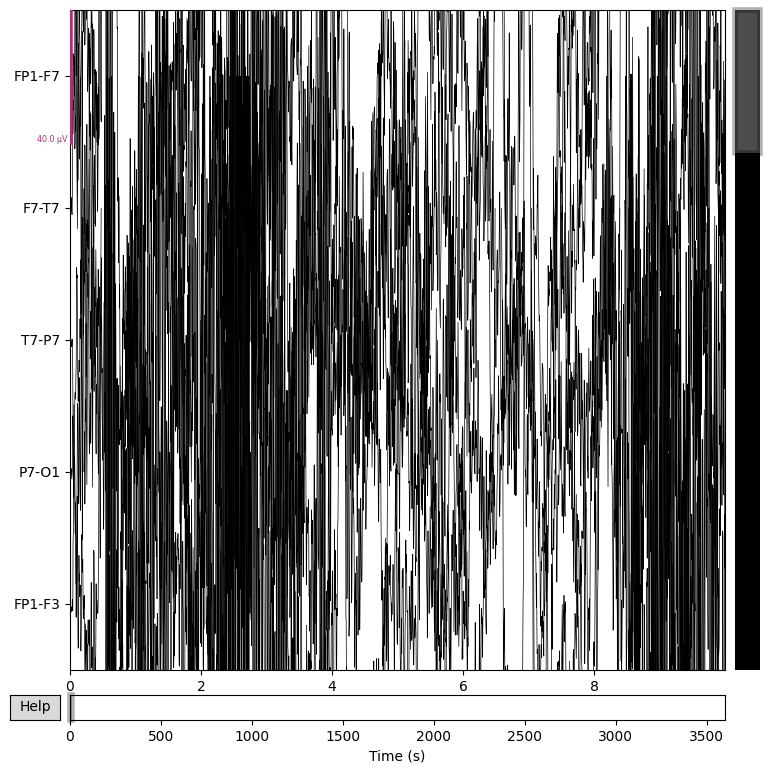

In [5]:
raw.plot(duration=10, n_channels=5)

In [6]:
data = raw.get_data()
data.shape

(23, 921600)

In [7]:
print("Número de canais: ", data.shape[0])
print("Número de amostras: ", data.shape[1])

Número de canais:  23
Número de amostras:  921600


Filtering raw data in 1 contiguous segment
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 1691 samples (6.605 s)

For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


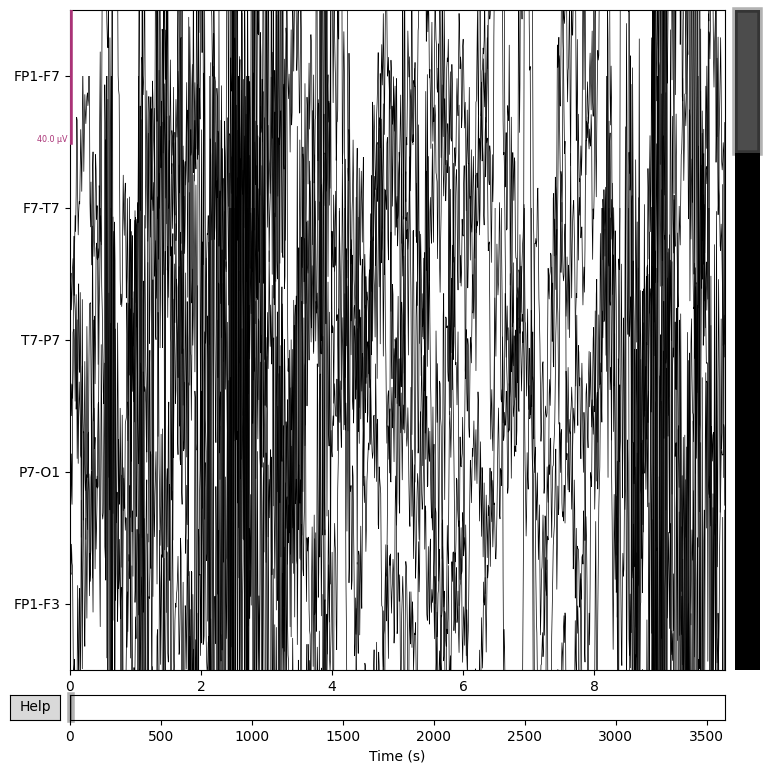

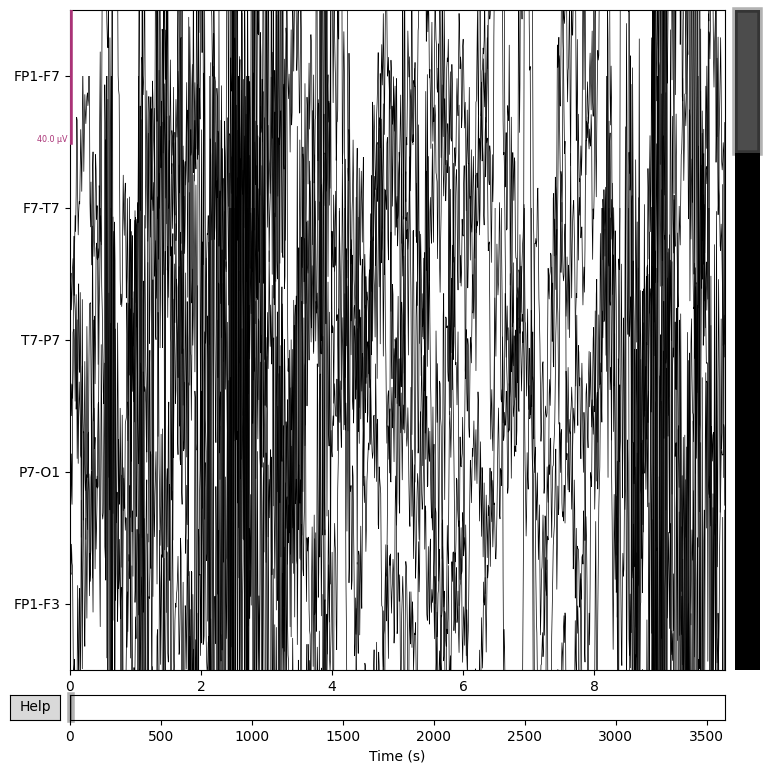

In [8]:
raw_filtrado = raw.copy().filter(0.5, 40)
raw_filtrado.plot(duration = 10, n_channels=5)

In [9]:
data_filtrado = raw_filtrado.get_data()
data_filtrado.shape

(23, 921600)

In [10]:
with open("chb24-summary.txt", "r") as f:
  conteudo = f.readlines()

  for linha in conteudo [:40]:
    print(linha.strip())

Data Sampling Rate: 256 Hz
*************************

Channels in EDF Files:
**********************
Channel 1: FP1-F7
Channel 2: F7-T7
Channel 3: T7-P7
Channel 4: P7-O1
Channel 5: FP1-F3
Channel 6: F3-C3
Channel 7: C3-P3
Channel 8: P3-O1
Channel 9: FP2-F4
Channel 10: F4-C4
Channel 11: C4-P4
Channel 12: P4-O2
Channel 13: FP2-F8
Channel 14: F8-T8
Channel 15: T8-P8
Channel 16: P8-O2
Channel 17: FZ-CZ
Channel 18: CZ-PZ
Channel 19: P7-T7
Channel 20: T7-FT9
Channel 21: FT9-FT10
Channel 22: FT10-T8
Channel 23: T8-P8

File Name: chb24_01.edf
Number of Seizures in File: 2
Seizure Start Time: 480 seconds
Seizure End Time: 505 seconds
Seizure Start Time: 2451 seconds
Seizure End Time: 2476 seconds

File Name: chb24_03.edf
Number of Seizures in File: 2
Seizure Start Time: 231 seconds
Seizure End Time: 260 seconds


In [11]:
seizure_intervals_sec = [
    (480, 505),
    (2451, 2476)
]

sfreq = raw.info["sfreq"]

In [12]:
canal_idx = 0
signal = data_filtrado[canal_idx]

In [13]:
time = np.arange(len(signal)) / sfreq

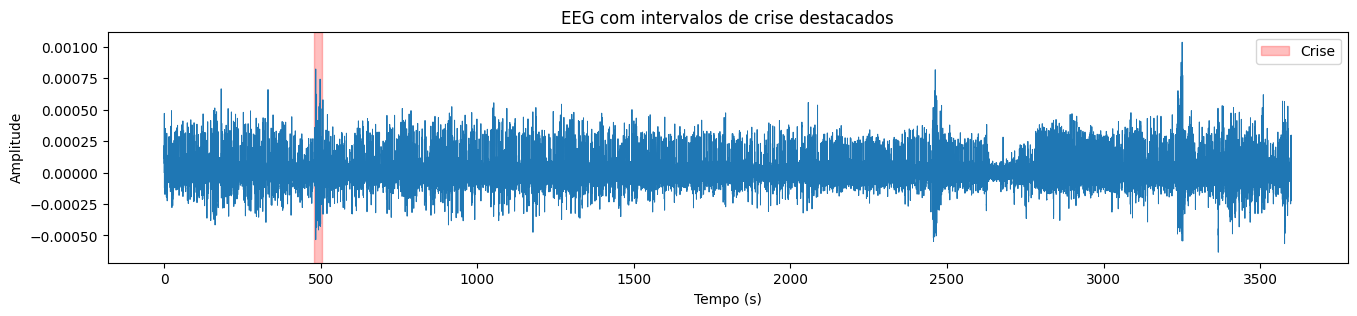

/tmp/ipykernel_2749/2883423333.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


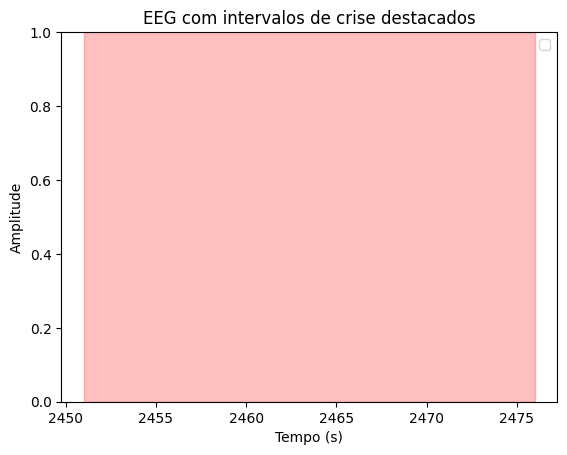

In [14]:
plt.figure(figsize=(16,3))
plt.plot(time, signal, linewidth=0.7)

for i,(start,end) in enumerate(seizure_intervals_sec):
  plt.axvspan(start, end, color="red", alpha=0.25, label="Crise" if i==0 else None)

  plt.xlabel("Tempo (s)")
  plt.ylabel("Amplitude")
  plt.title("EEG com intervalos de crise destacados")
  plt.legend()
  plt.show()

In [15]:
window_size = 256
step = 128

windows = []

for start in range(0, data_filtrado.shape[1] - window_size, step):
  segment = data_filtrado[:, start:start + window_size]
  windows.append(segment)

windows = np.array(windows)
windows.shape

(7198, 23, 256)

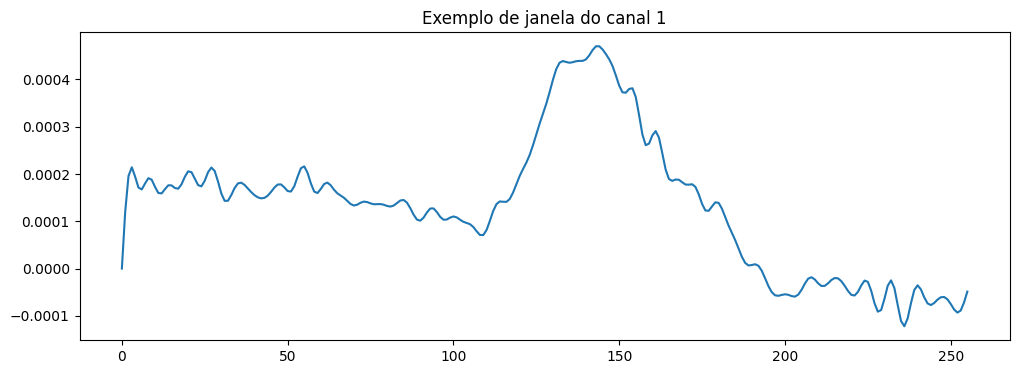

In [16]:
plt.figure(figsize=(12, 4))
plt.plot(windows[0][0])
plt.title("Exemplo de janela do canal 1")
plt.show()

In [17]:
print("Quantidade de janelas:", windows.shape[0])
print("Canais por janela:", windows.shape[1])
print("Amostras por janela:", windows.shape[2])

Quantidade de janelas: 7198
Canais por janela: 23
Amostras por janela: 256


In [18]:
features = []

for window in windows:
  feat = []
  feat.extend(window.mean(axis=1))
  feat.extend(window.std(axis=1))
  feat.extend(window.min(axis=1))
  feat.extend(window.max(axis=1))
  features.append(feat)

X = np.array(features)
X.shape

(7198, 92)

In [19]:
# lista onde vamos guardar o rotúlo de cada janela
labels = []

# percorre o sinal da mesma forma que críamos as janelas
for start in range(0, data_filtrado.shape[1] - window_size, step):

  end = start + window_size # Fim da janela

  #converte indice -> tempo (segundos)
  start_sec = start / sfreq
  end_sec = end / sfreq

  label = 0 # assume que é normal

  # verifica se a janela encosta em algun intervalo de crise
  for seizure_start, seizure_end in seizure_intervals_sec:

    overlap = (start_sec < seizure_end) and (end_sec > seizure_start)

    if overlap:
      label = 1 # marca como crise
      break

  labels.append(label) # salva rótulo da janela

# transforma em array
y = np.array(labels)

# resumo
print("Janelas totais:", len(y))
print("Janelas com crise:", y.sum())
print("Janelas normais:", (y==0).sum())


Janelas totais: 7198
Janelas com crise: 102
Janelas normais: 7096


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42)


In [21]:
from sklearn.tree import DecisionTreeClassifier

modelo_arvore = DecisionTreeClassifier(random_state=42)
modelo_arvore.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [22]:
from sklearn.metrics import accuracy_score

# o modelo faz previsões em dados que ele nunca viu (teste)
y_pred = modelo_arvore.predict(X_test)

# Comparando algumas previsões com o valor real
print("Comparação entre valor real e previsto:")
for i in range(10):
  print(f"Real: {y_test[i]} | Previsto: {y_pred[i]}")

  # calculando a acurácia (quantos ele acertou no total)
  acc_mlp = accuracy_score(y_test, y_pred)
  print("\nAcurácia do modelo:", acc_mlp)

Comparação entre valor real e previsto:
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778


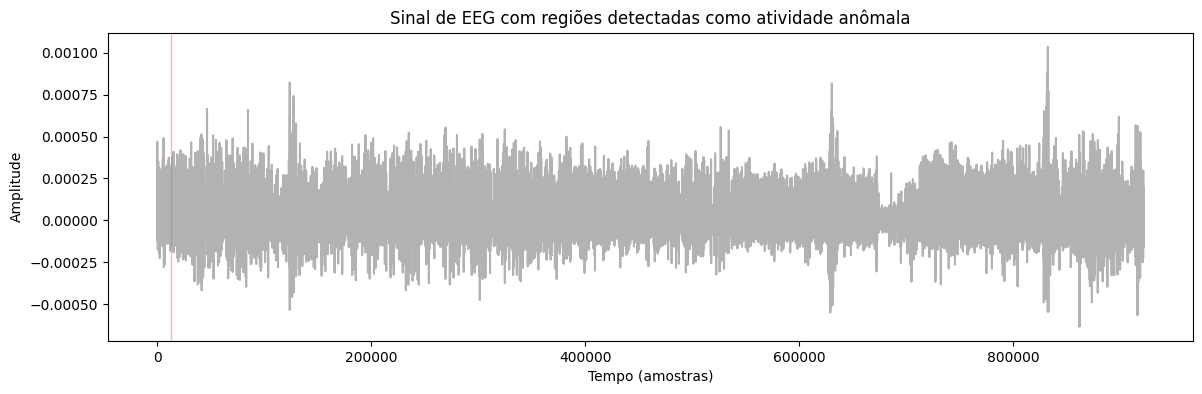

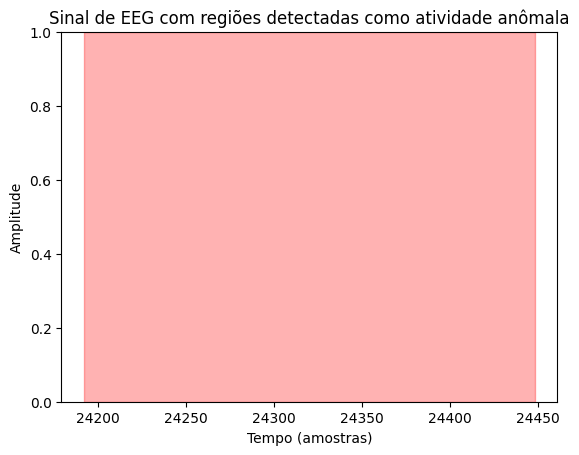

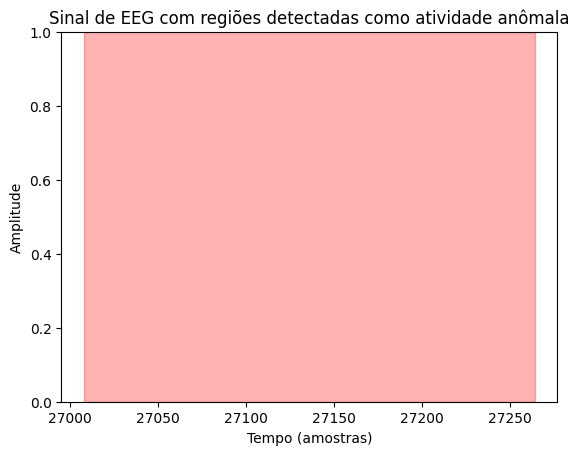

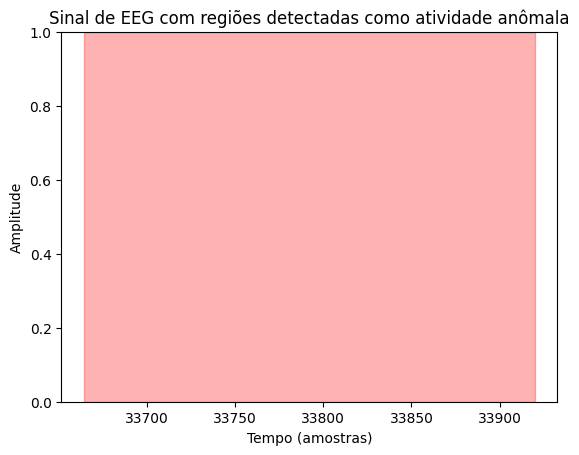

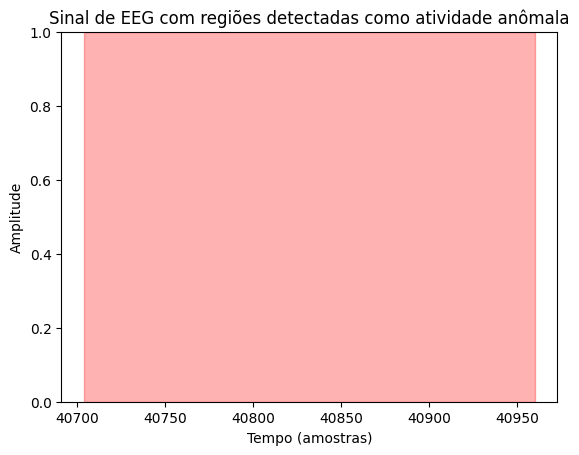

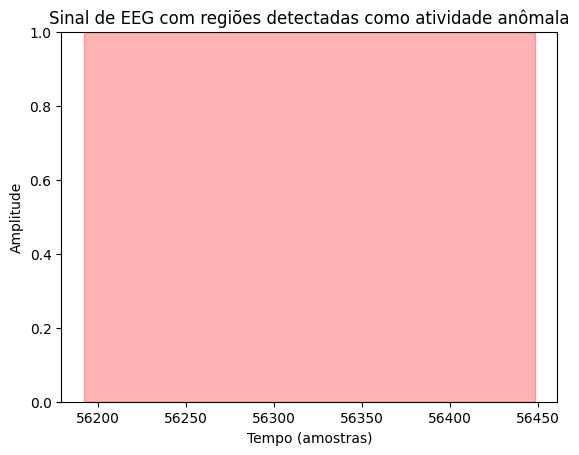

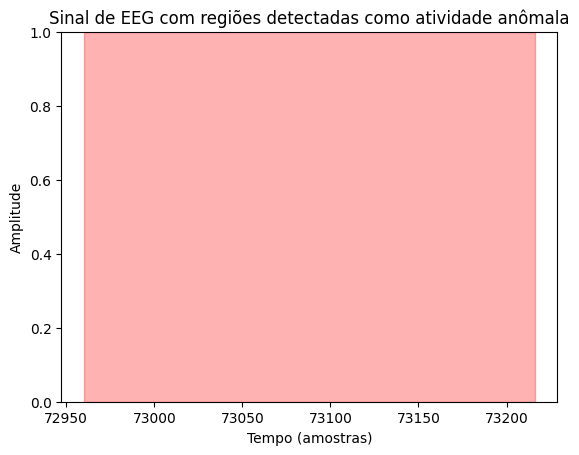

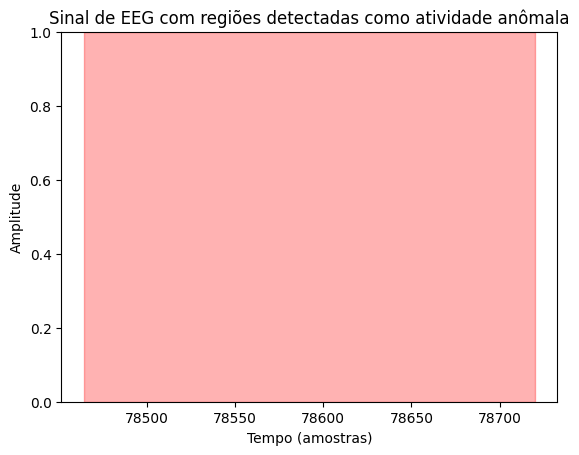

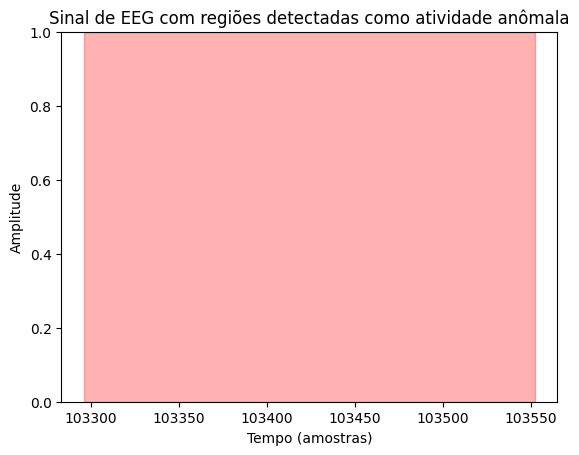

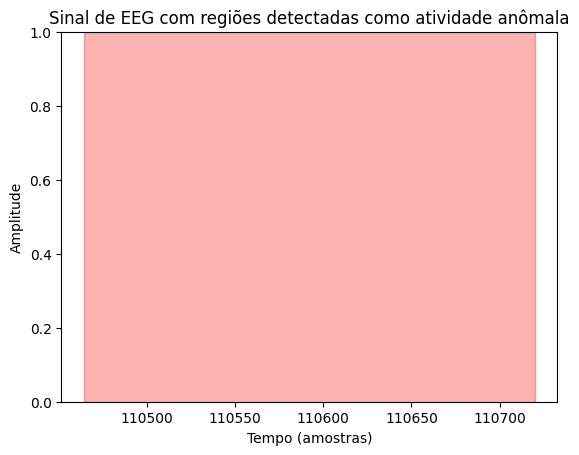

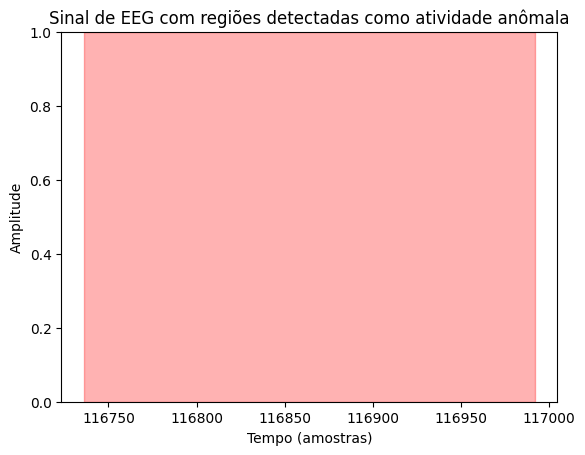

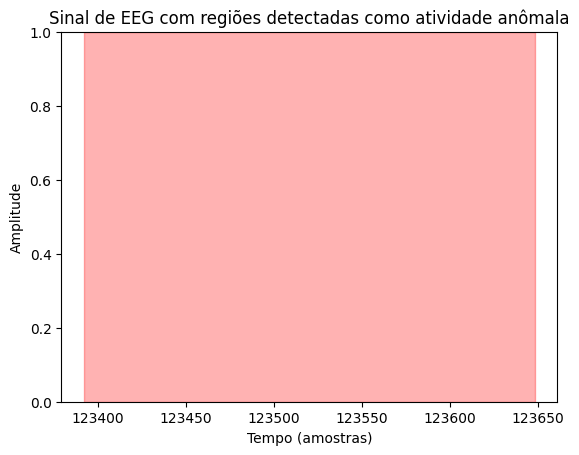

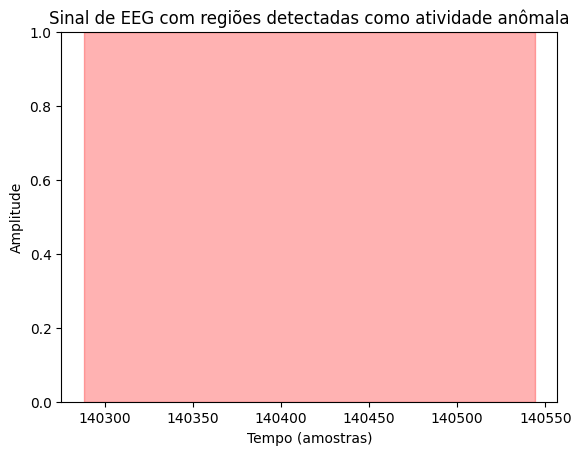

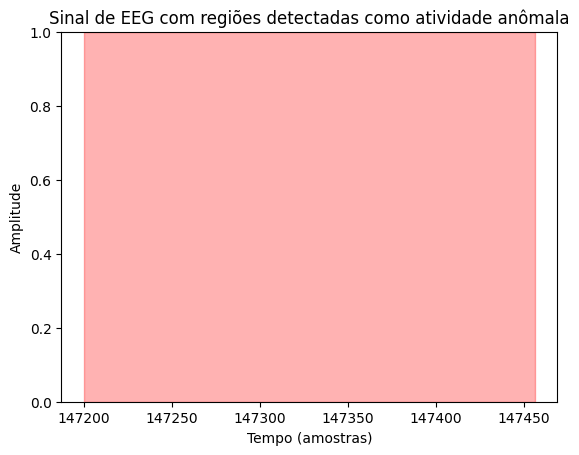

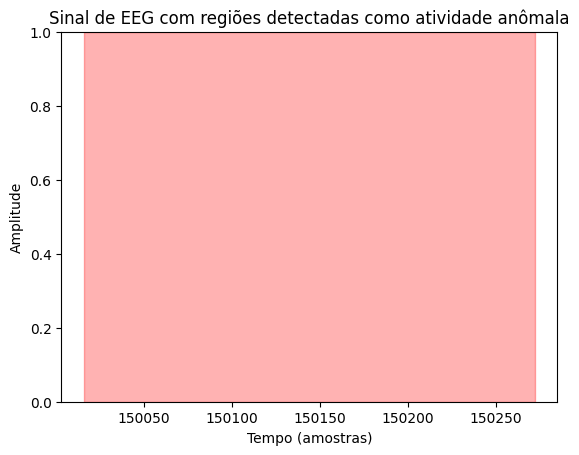

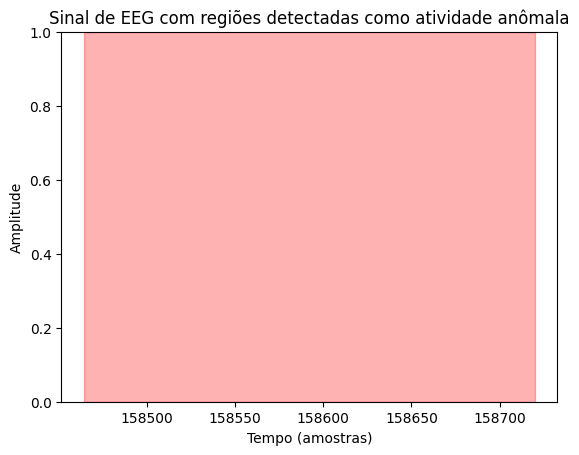

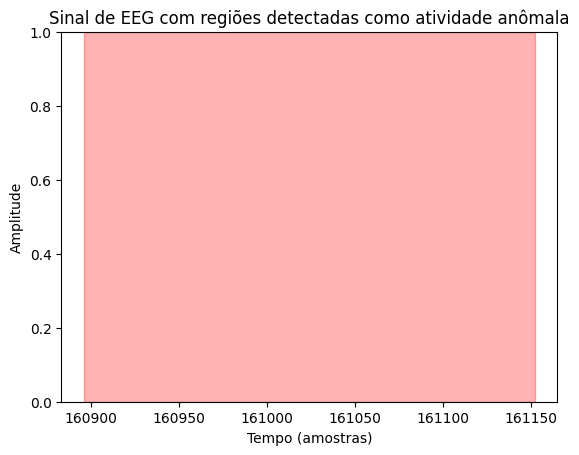

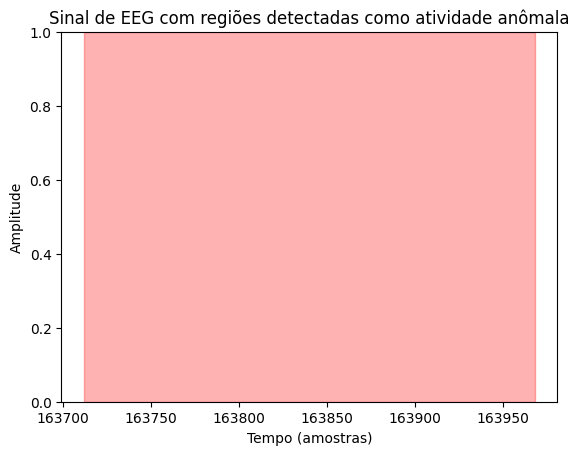

In [23]:
import matplotlib.pyplot as plt

# sinal de um canal para visualização
signal = data_filtrado[0]

plt.figure(figsize=(14,4))
plt.plot(signal, color='gray', alpha=0.6)

#desenhando janelas classificadas
for i, pred in enumerate(y_pred):

  start = i * step
  end = start + window_size

  if pred == 1: # classe anômala
    plt.axvspan(start, end, color='red', alpha=0.3)

    plt.title("Sinal de EEG com regiões detectadas como atividade anômala")
    plt.xlabel("Tempo (amostras)")
    plt.ylabel("Amplitude")

    plt.show()

In [24]:
amostra = X_test[0].reshape(1,-1)

pred = modelo_arvore.predict(amostra)[0]

print("Predição da amostra:", pred)

Predição da amostra: 0


# CÓDIGOS CRIADOS ACIMA SÃO PARA O MACHINE LEARNING ONDE CRIAMOS AS CARECTERÍSTICAS E O MODELO APRENDE ATRAVÉS DELA.

# ABAIXO SERÁ O APRENDIZADO PROFUNDO (DEEP LEARNING) QUE O PRÓPRIO MODELO APRENDE ATRAVÉS DAS REPRESENTAÇÕES.



In [25]:
amostra = X_test[0].reshape(1,-1)

pred = modelo_arvore.predict(amostra)[0]

print("Predição da amostra:", pred)


Predição da amostra: 0


In [26]:
from sklearn.neural_network import MLPClassifier

modelo_mlp = MLPClassifier(
    hidden_layer_sizes=(64,32),
    max_iter=300,
    random_state=42)


modelo_mlp.fit(X_train, y_train)

MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42)

In [27]:
y_pred_mlp = modelo_mlp.predict(X_test)

print("Comparação entre valor real e previsto(Rede Neural):")
for i in range(10):
  print(f"Real: {y_test[i]} | Previsto: {y_pred_mlp[i]}")

  acc = accuracy_score(y_test, y_pred_mlp)
  print("\nAcurácia do modelo:", acc_mlp)

Comparação entre valor real e previsto(Rede Neural):
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778
Real: 0 | Previsto: 0

Acurácia do modelo: 0.9902777777777778


In [28]:
print("Árvore de decisão:", acc)
print("Rede neural:", acc_mlp)

Árvore de decisão: 0.9847222222222223
Rede neural: 0.9902777777777778


In [29]:
X_dl = windows.transpose(0,2,1) # amostras, tempo, canais
X_dl.shape

(7198, 256, 23)

In [30]:
indice = 0
amostra_features = X_test[indice].reshape(1, -1)
pred_final = modelo_mlp.predict(amostra_features)[0]

print("Classe prevista:", pred_final)

Classe prevista: 0


In [31]:
media_amostra = float(np.mean(X_test[indice]))
desvio_amostra = float(np.std(X_test[indice]))
min_amostra = float(np.min(X_test[indice]))
max_amostra = float(np.max(X_test[indice]))

print(media_amostra, desvio_amostra, max_amostra, min_amostra)

4.685934950027717e-07 6.80675586891798e-05 0.00010835898116730831 -0.00025604746965517057


In [35]:
from openai import OpenAI
from google.colab import userdata

api_key = userdata.get('OPENAI_API')
client = OpenAI(api_key=api_key)

prompt = f"""
Um modelo de inteligencia artificial analisou o trecho de EEG.

Resumo da amostra:
- média: {media_amostra:.6f}
- desvio padrão: {desvio_amostra:.6f}
- valor mínimo: {min_amostra:.6f}
- valor máximo: {max_amostra:.6f}

Classe prevista: {pred_final}

Explique de forma simples e objetiva o que isso significa.
"""

response = client.responses.create(
    model="gpt-4o-mini",
    input=prompt

)

explicacao = response.output[0].content[0].text

print("\nExplicação da IA:\n")
print(explicacao)


Explicação da IA:

Esse resumo de EEG (eletroencefalograma) mostra que a atividade elétrica do cérebro analisada nessa amostra é muito baixa e está próxima de zero, com uma média de 0. Isso indica que não há muitas variações significativas na atividade cerebral durante o período medido.

Os valores mínimo e máximo sugerem que a atividade do cérebro teve oscilações muito pequenas, entre -0,000256 e 0,000108. O desvio padrão, que é muito pequeno (0,000068), confirma que esses dados estão muito concentrados em torno da média.

A classe prevista como "0" sugere que, com base nas características dessa atividade cerebral, o modelo classificou essa amostra como pertencente a um grupo específico, possivelmente relacionado a um estado de descanso ou baixa atividade cerebral.
